In [1]:
import numpy as np
import glob
import matplotlib.pyplot as plt
import netCDF4 as nc4
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import MaxNLocator
import matplotlib.ticker as mticker
import jdcal
import pickle as pkl
import math
import sim_name_remap as snr

In [2]:
# Scale height functions

def alt2prs(alts, H, P0):
    result = P0*np.exp(-1.0*alts/H)
    return result
      
def prs2alt(prs, H, P0):
    result = -1.0*H*np.log(prs/P0)
    return result

In [3]:

sims = ['2022_M2-weak','2022_M2-strong','2022_E5-weak','2022_E5-strong','2022_FreeRun']

date0 = '2022-05-01'
date1 = '2022-09-30'
region = [0,360,-20,20]  # Global tropics
let='(a)'

#date0 = '2022-08-01'
#date1 = '2022-08-31'
##region = [30,130,25,45]  # Full ASM anticyclone
#region = [95,135,30,50]  # East Asia box
#let='(b)'

#prec_thresh = 0.75  # mm/hr, for the ASM (see Pfister et al 2022 Table 1)
#####prec_thresh = 1.0   # mm/hr, as a general approximation for everywhere   ##### Should be this, maybe
#prec_thresh = 1.5   # mm/hr, for the tropics (see Pfister et al 2022 Table 1)
prec_thresh = -999


In [4]:

# Retreive cloud observations
cld_file = '/glade/work/wsmith/cloud_data_file_final.pkl'
with open(cld_file, 'rb') as f: cloud_jd, cloudlon, cloudlat, cloudalt, cloudtheta, trop_alt, trop_theta = pkl.load(f)

lonind0 = np.where(cloudlon >= region[0])[0][0]
lonind1 = np.where(cloudlon <= region[1])[0][-1]
latind0 = np.where(cloudlat >= region[2])[0][0]
latind1 = np.where(cloudlat <= region[3])[0][-1]

# Convert date range to JD
cloud_jd = np.asarray(cloud_jd)
init_jd = sum(jdcal.gcal2jd(int(date0[0:4]), int(date0[5:7]), int(date0[8:])))
end_jd  = sum(jdcal.gcal2jd(int(date1[0:4]), int(date1[5:7]), int(date1[8:]))) + 0.875
tind0 = list(cloud_jd).index(init_jd)
tind1 = list(cloud_jd).index(end_jd)

cldalt_subset = cloudalt[tind0:tind1+1,latind0:latind1+1,lonind0:lonind1+1]
#cldprs_subset = alt2prs(cldalt_subset, 7.6, 1013.)

#print(np.shape(cldprs_subset))
#print(np.min(cldprs_subset), np.max(cldprs_subset))

cldalt_subset = np.asarray(cldalt_subset.flatten())

obspct = len(np.where(cldalt_subset >= 12.00)[0])*100./len(cldalt_subset)
obspct = str(round(obspct,1))
print(obspct)


3.0


In [5]:

def get_model_clouds(sim, date0, date1, region, prec_thresh):
    
    sim_path = snr.remap[sim]
    sim_files = sorted(glob.glob(sim_path))

    sim_files0 = [item for item in sim_files if date0 in item][0]
    find0 = list(sim_files).index(sim_files0)
    sim_files1 = [item for item in sim_files if date1 in item][0]
    find1 = list(sim_files).index(sim_files1)
    
    sim_files = sim_files[find0:find1+1]
    
    cloudtops = []
    conv_precip = []
    
    for f in range(len(sim_files)):
    
        file = nc4.Dataset(sim_files[f])
        lon = file.variables['lon'][:]
        lat = file.variables['lat'][:]
    
        lon_ind0 = np.min(np.where(lon >= region[0])[0])
        lon_ind1 = np.max(np.where(lon <= region[1])[0])+1
        lat_ind0 = np.min(np.where(lat >= region[2])[0])
        lat_ind1 = np.max(np.where(lat <= region[3])[0])+1
    
        #curr_cloudtop = file.variables['PCONVT'][:,lat_ind0:lat_ind1,lon_ind0:lon_ind1]/100.
        curr_cloudtop = file.variables['CLDHGT'][:,lat_ind0:lat_ind1,lon_ind0:lon_ind1]
        curr_convprec = file.variables['PRECC'][:,lat_ind0:lat_ind1,lon_ind0:lon_ind1]*1000.*3600.  # Convert to mm/hr
        
        cloudtops.append(np.asarray(curr_cloudtop).flatten())
        conv_precip.append(np.asarray(curr_convprec).flatten())
    
    cloudtops = np.asarray(cloudtops).flatten()
    conv_precip = np.asarray(conv_precip).flatten()

    simpct = len(np.where(cloudtops >= 12.00)[0])*100./len(cloudtops)
    simpct = str(round(simpct,1))
    print(sim, ':' , simpct)
    
    cloudtops_conv = []
    
    for pt in range(len(conv_precip)):
        if conv_precip[pt] >= prec_thresh: cloudtops_conv.append(cloudtops[pt])  # Choose convective precip > 5 mm/day which is arbitrary

    #cloudtops_conv = prs2alt(np.asarray(cloudtops_conv),7.6,1013.)

    print(sim, 'completed')
    
    return np.asarray(cloudtops_conv), simpct


In [6]:

cldtops0, pct0 = get_model_clouds(sims[0], date0, date1, region, prec_thresh)
cldtops1, pct1 = get_model_clouds(sims[1], date0, date1, region, prec_thresh)
cldtops2, pct2 = get_model_clouds(sims[2], date0, date1, region, prec_thresh)
cldtops3, pct3 = get_model_clouds(sims[3], date0, date1, region, prec_thresh)
cldtops4, pct4 = get_model_clouds(sims[4], date0, date1, region, prec_thresh)


2022_M2-weak : 0.9
2022_M2-weak completed
2022_M2-strong : 1.7
2022_M2-strong completed
2022_E5-weak : 1.2
2022_E5-weak completed
2022_E5-strong : 2.8
2022_E5-strong completed
2022_FreeRun : 0.6
2022_FreeRun completed


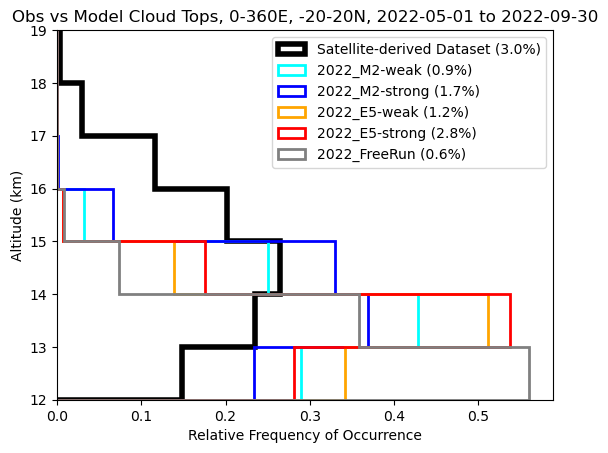

In [7]:

fig = plt.figure()
ax = fig.add_subplot(111)

#linbins = np.arange(50,1001,50)
#logbins = np.logspace(np.log10(50), np.log10(1000), num=19)
#obscld_counts, bins = np.histogram(cldalt_subset.flatten(), bins=logbins, density=False) # We separate these so we can scale the observations by 1/18 (grid size disparity compared to 0.9x1.25)
#plt.hist(bins[:-1], bins, weights=obscld_counts, color = 'black', linewidth=3,
#    histtype = 'step', orientation='horizontal', label='Satellite-derived Dataset')   # range = [50,1000],

altbins = np.arange(12,19.1,1)
plt.hist(cldalt_subset, bins=altbins, color='black', density=True, linewidth=4, 
         histtype='step', label='Satellite-derived Dataset (' + obspct + '%)', orientation='horizontal')

plt.hist(cldtops0, bins=altbins, density = True, color = 'cyan', linewidth=2,
        histtype = 'step', orientation='horizontal', label=sims[0] + ' (' + pct0 + '%)')  # range=[50,1000],
plt.hist(cldtops1, bins=altbins, density = True, color = 'blue', linewidth=2,
        histtype = 'step', orientation='horizontal', label=sims[1] + ' (' + pct1 + '%)')  # range=[50,1000],
plt.hist(cldtops2, bins=altbins, density = True, color = 'orange', linewidth=2,
        histtype = 'step', orientation='horizontal', label=sims[2] + ' (' + pct2 + '%)')  # range=[50,1000],
plt.hist(cldtops3, bins=altbins, density = True, color = 'red', linewidth=2,
        histtype = 'step', orientation='horizontal', label=sims[3] + ' (' + pct3 + '%)')  # range=[50,1000],
plt.hist(cldtops4, bins=altbins, density = True, color = 'gray', linewidth=2,
        histtype = 'step', orientation='horizontal', label=sims[4] + ' (' + pct4 + '%)')  # range=[50,1000],

#plt.yscale('log')
#plt.ylim(1000,70)
plt.ylim(12,19)

plt.title('Obs vs Model Cloud Tops, ' + str(region[0]) + '-' + str(region[1]) + 'E, ' + str(region[2]) + '-' + str(region[3]) + 'N, ' + date0 + ' to ' + date1)
#plt.ylabel('Pressure (hPa)')
plt.ylabel('Altitude (km)')
plt.xlabel('Relative Frequency of Occurrence')  # For density=True
plt.legend(loc='upper right')
#plt.yticks([1000,700,500,300,100])

plt.savefig('/glade/u/home/wsmith/NudgeComparison_scripts/plots/Figure2.png')
plt.savefig('/glade/u/home/wsmith/NudgeComparison_scripts/plots/Figure2.pdf')


In [8]:
#print(hist4)

In [9]:
#print(hist1)